In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw_student_data.csv")

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [2]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all"))

Dataset shape: (1000, 8)

Column names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB

Missing values:
gender                         0
race/ethnicity                 0
parental l

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
count,1000,1000,1000,1000,1000,1000.00000,1000.000000,1000.000000
unique,2,5,6,2,2,NaN,NaN,NaN
top,female,group C,some college,standard,none,NaN,NaN,NaN
freq,518,319,226,645,642,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,66.08900,69.169000,68.054000
std,NaN,NaN,NaN,NaN,NaN,15.16308,14.600192,15.195657
min,NaN,NaN,NaN,NaN,NaN,0.00000,17.000000,10.000000
25%,NaN,NaN,NaN,NaN,NaN,57.00000,59.000000,57.750000
50%,NaN,NaN,NaN,NaN,NaN,66.00000,70.000000,69.000000
75%,NaN,NaN,NaN,NaN,NaN,77.00000,79.000000,79.000000


In [3]:

# STEP 3: DATA VALIDATION

# 1. Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# 2. Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# 3. Check data types
print("\nColumn data types:")
print(df.dtypes)

# 4. Check whether marks are within 0-100
score_columns = ["math score", "reading score", "writing score"]

for col in score_columns:
    invalid = df[~df[col].between(0, 100)]
    print(f"{col}: {len(invalid)} invalid scores")

# 5. Check valid category values
category_columns = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

for col in category_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


Missing values in each column:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Number of duplicate rows: 0

Column data types:
gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object
math score: 0 invalid scores
reading score: 0 invalid scores
writing score: 0 invalid scores

gender:
gender
female    518
male      482
Name: count, dtype: int64

race/ethnicity:
race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

parental level of education:
parenta

In [4]:

# STEP 4: DATA CLEANING AND FEATURE ENGINEERING

# Keep the original dataset unchanged
cleaned_df = df.copy()

# Standardize column names
cleaned_df.columns = (
    cleaned_df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Define subject columns
score_columns = ["math_score", "reading_score", "writing_score"]

# Calculate total and average marks
cleaned_df["total_marks"] = cleaned_df[score_columns].sum(axis=1)
cleaned_df["average_marks"] = cleaned_df[score_columns].mean(axis=1).round(2)

# Assign grades based on average marks
def assign_grade(average):
    if average >= 80:
        return "A"
    elif average >= 60:
        return "B"
    elif average >= 40:
        return "C"
    else:
        return "Fail"

cleaned_df["grade"] = cleaned_df["average_marks"].apply(assign_grade)

# Save the cleaned dataset
cleaned_df.to_csv("../data/cleaned_student_data.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Dataset shape:", cleaned_df.shape)
display(cleaned_df.head())


Cleaned dataset saved successfully!
Dataset shape: (1000, 11)


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_marks,average_marks,grade
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.67,B
1,female,group C,some college,standard,completed,69,90,88,247,82.33,A
2,female,group B,master's degree,standard,none,90,95,93,278,92.67,A
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.33,C
4,male,group C,some college,standard,none,76,78,75,229,76.33,B


In [5]:
print("New columns:")
print(cleaned_df.columns.tolist())

print("\nGrade distribution:")
print(cleaned_df["grade"].value_counts().sort_index())

print("\nAverage marks statistics:")
print(cleaned_df["average_marks"].describe())

print("\nSaved file exists:")
from pathlib import Path
print(Path("../data/cleaned_student_data.csv").exists())

New columns:
['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score', 'total_marks', 'average_marks', 'grade']

Grade distribution:
grade
A       198
B       517
C       255
Fail     30
Name: count, dtype: int64

Average marks statistics:
count    1000.000000
mean       67.770580
std        14.257311
min         9.000000
25%        58.330000
50%        68.330000
75%        77.670000
max       100.000000
Name: average_marks, dtype: float64

Saved file exists:
True


In [6]:

# STEP 5A: KEY PERFORMANCE INDICATORS

score_columns = ["math_score", "reading_score", "writing_score"]

print("STUDENT PERFORMANCE SUMMARY")
print("=" * 35)

print("Total records:", len(cleaned_df))
print("Overall average marks:", round(cleaned_df["average_marks"].mean(), 2))
print("Median average marks:", round(cleaned_df["average_marks"].median(), 2))
print("Highest average marks:", cleaned_df["average_marks"].max())
print("Lowest average marks:", cleaned_df["average_marks"].min())

# Pass is defined as an average of at least 40
pass_count = (cleaned_df["average_marks"] >= 40).sum()
pass_percentage = pass_count / len(cleaned_df) * 100

print("Pass count:", pass_count)
print("Fail count:", len(cleaned_df) - pass_count)
print("Pass percentage:", round(pass_percentage, 2), "%")

print("\nSUBJECT-WISE STATISTICS")
display(cleaned_df[score_columns].describe().round(2))

print("\nGRADE DISTRIBUTION")
grade_summary = cleaned_df["grade"].value_counts().reindex(
    ["A", "B", "C", "Fail"], fill_value=0
)
grade_summary = grade_summary.to_frame(name="student_count")
grade_summary["percentage"] = (
    grade_summary["student_count"] / len(cleaned_df) * 100
).round(2)

display(grade_summary)


STUDENT PERFORMANCE SUMMARY
Total records: 1000
Overall average marks: 67.77
Median average marks: 68.33
Highest average marks: 100.0
Lowest average marks: 9.0
Pass count: 970
Fail count: 30
Pass percentage: 97.0 %

SUBJECT-WISE STATISTICS


,math_score,reading_score,writing_score
count,1000.00,1000.00,1000.00
mean,66.09,69.17,68.05
std,15.16,14.60,15.20
min,0.00,17.00,10.00
25%,57.00,59.00,57.75
50%,66.00,70.00,69.00
75%,77.00,79.00,79.00
max,100.00,100.00,100.00



GRADE DISTRIBUTION


,student_count,percentage
grade,,
A,198,19.8
B,517,51.7
C,255,25.5
Fail,30,3.0


reading_score    69.17
writing_score    68.05
math_score       66.09
dtype: float64


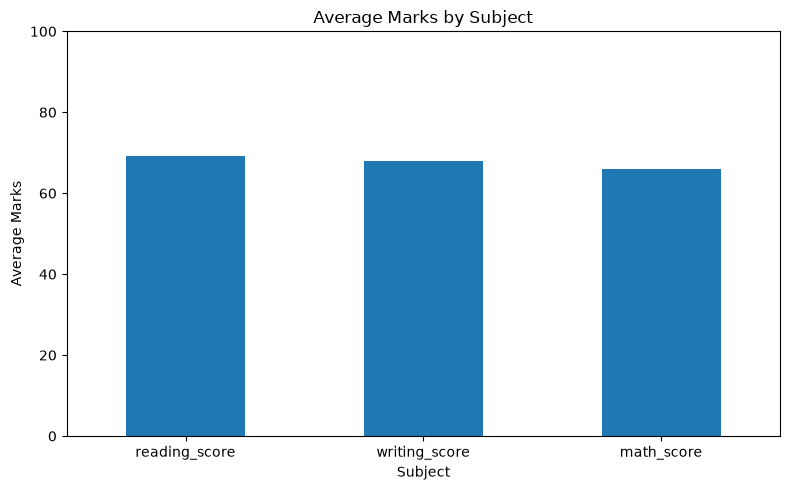

In [7]:

# Subject-wise average marks
subject_averages = cleaned_df[score_columns].mean().sort_values(
    ascending=False
)

print(subject_averages.round(2))

plt.figure(figsize=(8, 5))
subject_averages.plot(kind="bar")
plt.title("Average Marks by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Marks")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [8]:
plt.savefig("../charts/subject_average.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

Average marks by test preparation status:


,math_score,reading_score,writing_score,average_marks
test_preparation_course,,,,
completed,69.70,73.89,74.42,72.67
none,64.08,66.53,64.50,65.04


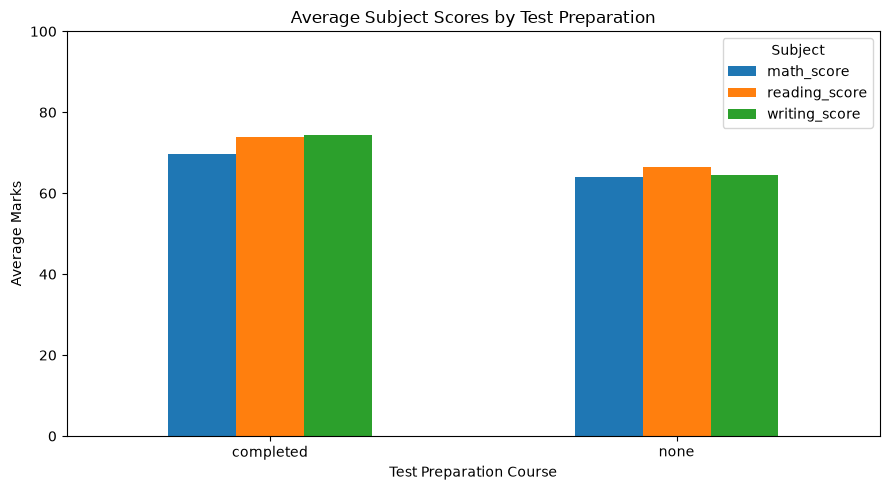

In [9]:

# STEP 6A: TEST PREPARATION ANALYSIS

prep_summary = cleaned_df.groupby("test_preparation_course")[
    ["math_score", "reading_score", "writing_score", "average_marks"]
].mean().round(2)

print("Average marks by test preparation status:")
display(prep_summary)

prep_summary[["math_score", "reading_score", "writing_score"]].plot(
    kind="bar", figsize=(9, 5)
)

plt.title("Average Subject Scores by Test Preparation")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Marks")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Subject")
plt.tight_layout()
plt.savefig("../charts/test_preparation_comparison.png", dpi=300)
plt.show()


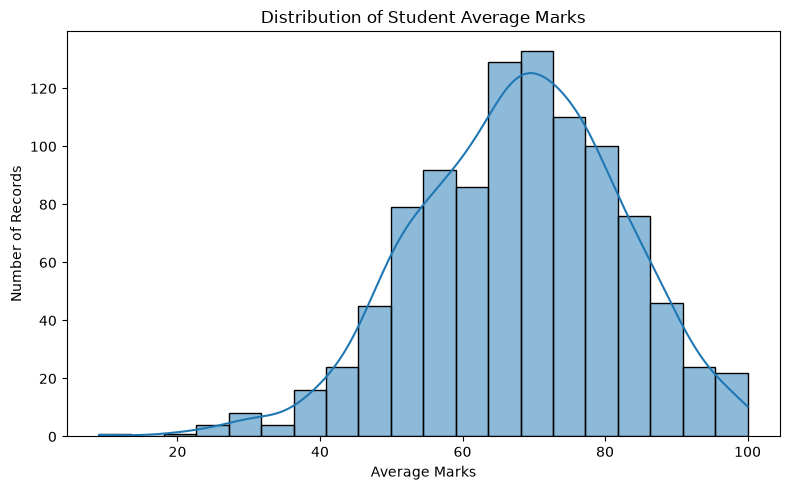

In [10]:

# STEP 6B: DISTRIBUTION OF AVERAGE MARKS

plt.figure(figsize=(8, 5))

sns.histplot(
    data=cleaned_df,
    x="average_marks",
    bins=20,
    kde=True
)

plt.title("Distribution of Student Average Marks")
plt.xlabel("Average Marks")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig("../charts/average_marks_distribution.png", dpi=300)
plt.show()


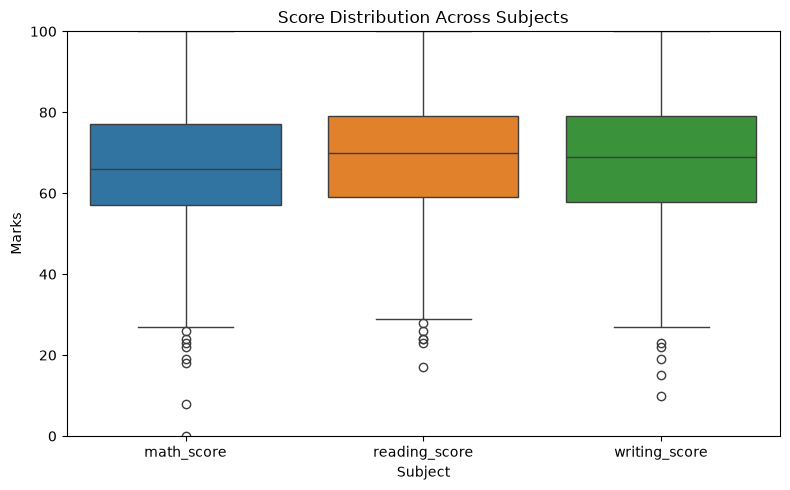

In [11]:

# STEP 6C: SUBJECT SCORE BOXPLOT

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=cleaned_df[
        ["math_score", "reading_score", "writing_score"]
    ]
)

plt.title("Score Distribution Across Subjects")
plt.xlabel("Subject")
plt.ylabel("Marks")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("../charts/subject_score_boxplot.png", dpi=300)
plt.show()


               math_score  reading_score  writing_score
math_score          1.000          0.818          0.803
reading_score       0.818          1.000          0.955
writing_score       0.803          0.955          1.000


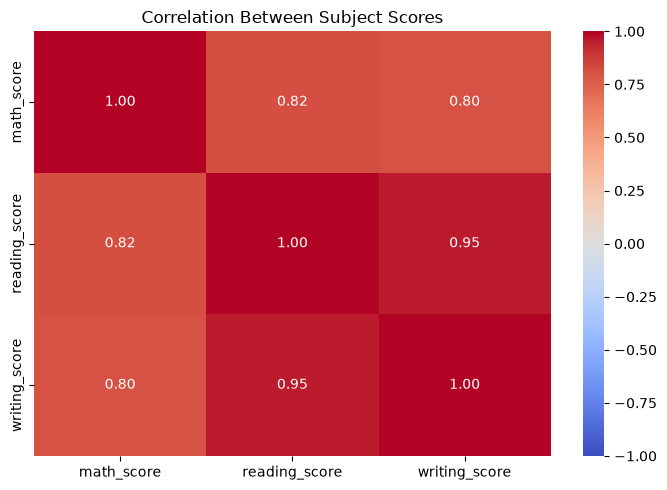

In [12]:

# STEP 6D: SUBJECT CORRELATION HEATMAP

correlation = cleaned_df[
    ["math_score", "reading_score", "writing_score"]
].corr()

print(correlation.round(3))

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Subject Scores")
plt.tight_layout()
plt.savefig("../charts/subject_correlation_heatmap.png", dpi=300)
plt.show()
